In [27]:
import pandas as pd

fake = pd.read_csv(r"./Data/Fake.csv")
real = pd.read_csv(r"./Data/True.csv")

fake


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"
...,...,...,...,...
23476,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016"
23477,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016"
23478,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016"
23479,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016"


In [28]:
fake['label'] = 0
real['label'] = 1

In [29]:
data = pd.concat([fake, real], ignore_index=True)
data

,title,text,subject,date,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0
...,...,...,...,...,...
44893,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017",1
44894,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017",1
44895,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017",1
44896,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017",1


In [30]:
data.shape

(44898, 5)

In [31]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    44898 non-null  str  
 1   text     44898 non-null  str  
 2   subject  44898 non-null  str  
 3   date     44898 non-null  str  
 4   label    44898 non-null  int64
dtypes: int64(1), str(4)
memory usage: 1.7 MB


In [32]:
data.drop(columns= ['date'], inplace=True)

In [33]:
data.isnull().sum()

title      0
text       0
subject    0
label      0
dtype: int64

In [34]:
print("total duplicates :", data.duplicated().sum())
data.drop_duplicates(inplace=True)



total duplicates : 213


In [35]:
data['subject'].value_counts()

subject
politicsNews       11217
worldnews           9991
News                9050
politics            6838
left-news           4458
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64

In [36]:
# Combine all 3 columns before NLP preprocessing
from Feature_Engineering.functions import (combine)
data["combined_text"] = (
    combine(data["text"],data["title"],data["subject"])
)

# Check
print(data["combined_text"].head())
data.drop(columns=["text","title","subject"],inplace=True)

0    Donald Trump just couldn t wish all Americans ...
1    House Intelligence Committee Chairman Devin Nu...
2    On Friday, it was revealed that former Milwauk...
3    On Christmas day, Donald Trump announced that ...
4    Pope Francis used his annual Christmas Day mes...
Name: combined_text, dtype: str


In [41]:
from Feature_Engineering.functions import (lower)
data['combined_text'] = data['combined_text'].apply(lower)

In [42]:
from Feature_Engineering.functions import remove_punc
data['combined_text'] = data['combined_text'].apply(remove_punc)


In [44]:
from Feature_Engineering.functions import remove_numbers
data['combined_text'] = data['combined_text'].apply(remove_numbers)

In [45]:
from Feature_Engineering.functions import emoji_is
data['combined_text'] = data['combined_text'].apply(emoji_is)
 

       

In [49]:
from Feature_Engineering.functions import remove_words
data['combined_text'] = data['combined_text'].apply(remove_words)


In [50]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(data["combined_text"], data["label"], test_size =0.2, random_state=42)

In [51]:
print(X_train.shape)
print(Y_train.shape)

(35748,)
(35748,)


In [52]:
from sklearn.feature_extraction.text import CountVectorizer
import joblib
bow_vectorizer = CountVectorizer()

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

joblib.dump(bow_vectorizer,"./Preprocessor/bow_vectorizer.pkl")

['./Preprocessor/bow_vectorizer.pkl']

In [53]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score ,recall_score,precision_score,f1_score

mnb_bow = MultinomialNB()
mnb_bow.fit(X_train_bow, Y_train)

acc_mnb_bow=accuracy_score(Y_test,mnb_bow.predict(X_test_bow))
prec_mnb_bow=precision_score(Y_test,mnb_bow.predict(X_test_bow))
recall_mnb_bow=recall_score(Y_test,mnb_bow.predict(X_test_bow))
f1_mnb_bow=f1_score(Y_test,mnb_bow.predict(X_test_bow))

In [54]:
from sklearn.linear_model import LogisticRegression

le_bow =  LogisticRegression()
le_bow.fit(X_train_bow, Y_train) 


acc_le_bow=accuracy_score(Y_test,le_bow.predict(X_test_bow))
prec_le_bow=precision_score(Y_test,le_bow.predict(X_test_bow))
recall_le_bow=recall_score(Y_test,le_bow.predict(X_test_bow))
f1_le_bow=f1_score(Y_test,le_bow.predict(X_test_bow))

In [55]:
print(X_train_bow.shape)
print(Y_train.shape)

(35748, 194480)
(35748,)


In [56]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [57]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score ,recall_score,precision_score,f1_score

mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, Y_train)

acc_mnb_tfidf=accuracy_score(Y_test,mnb_tfidf.predict(X_test_tfidf))
prec_mnb_tfidf=precision_score(Y_test,mnb_tfidf.predict(X_test_tfidf))
recall_mnb_tfidf=recall_score(Y_test,mnb_tfidf.predict(X_test_tfidf))
f1_mnb_tfidf=f1_score(Y_test,mnb_tfidf.predict(X_test_tfidf))

mnb_tfidf.predict(X_test_tfidf)

array([0, 1, 1, ..., 1, 0, 1], shape=(8937,))

In [58]:
from sklearn.linear_model import LogisticRegression

le_tfidf =  LogisticRegression()
le_tfidf.fit(X_train_tfidf, Y_train) 


acc_le_tfidf=accuracy_score(Y_test,le_tfidf.predict(X_test_tfidf))
prec_le_tfidf=precision_score(Y_test,le_tfidf.predict(X_test_tfidf))
recall_le_tfidf=recall_score(Y_test,le_tfidf.predict(X_test_tfidf))
f1_le_tfidf=f1_score(Y_test,le_tfidf.predict(X_test_tfidf))


In [59]:
comparison_table = pd.DataFrame({"Models": ["Logistic Regression Bag of Words", "Multinomial NB Bag of words","Logistic Regression TF-IDF","Multinomial NB TF-IDF"],
                    "Accuracy" : [acc_le_bow,acc_mnb_bow,acc_le_tfidf,acc_mnb_tfidf],
                    "Precision": [prec_le_bow, prec_mnb_bow, prec_le_tfidf, prec_le_tfidf],
                    "Recall" : [recall_le_bow, recall_mnb_bow, recall_le_tfidf, recall_mnb_tfidf],
                    "F1-Score": [f1_le_bow, f1_mnb_bow, f1_le_tfidf, f1_mnb_tfidf]})
comparison_table.to_csv("./Processed_Data/comparison_table.csv",index=False)

In [60]:
import joblib

joblib.dump(le_bow,"./Preprocessor/model.pkl")

['./Preprocessor/model.pkl']

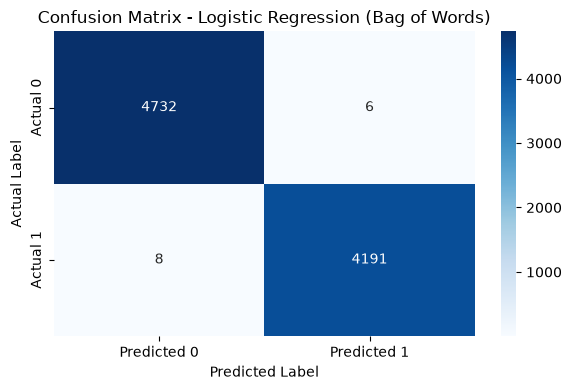

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.metrics import confusion_matrix

# Predict on test data
Y_pred_le_bow = le_bow.predict(X_test_bow)

# Create confusion matrix
cm = confusion_matrix(Y_test, Y_pred_le_bow)

# Plot confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Logistic Regression (Bag of Words)")
plt.tight_layout()
plt.show()

In [62]:
cm_table = pd.DataFrame(cm)

In [63]:
cm_table.to_csv("./Processed_Data/cm_table.csv",index=False)